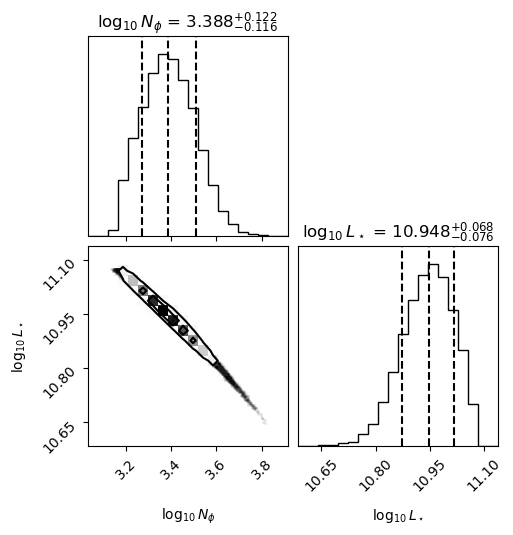

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import corner

d = np.load("/global/u1/z/zhaozhon/project/results/mcmc/per_bin/order1_all/y3_bin2_z2.4-2.5_all_order1_w10000_s10000_c4.npz")


logN = d["log_Nphi"] / np.log(10.0)
logL = d["log_Lstar"] / np.log(10.0)

samples2 = np.column_stack([logN, logL])

ranges2 = []
for j in range(samples2.shape[1]):
    v = samples2[:, j]
    lo, hi = v.min(), v.max()
    pad = 0.15 * (hi - lo)
    ranges2.append((lo - pad, hi + pad))

fig = corner.corner(
    samples2,
    labels=[r"$\log_{10} N_\phi$", r"$\log_{10} L_\star$"],
    range=ranges2,
    show_titles=True,
    title_fmt=".3f",
    quantiles=[0.16, 0.5, 0.84],
)
plt.show()

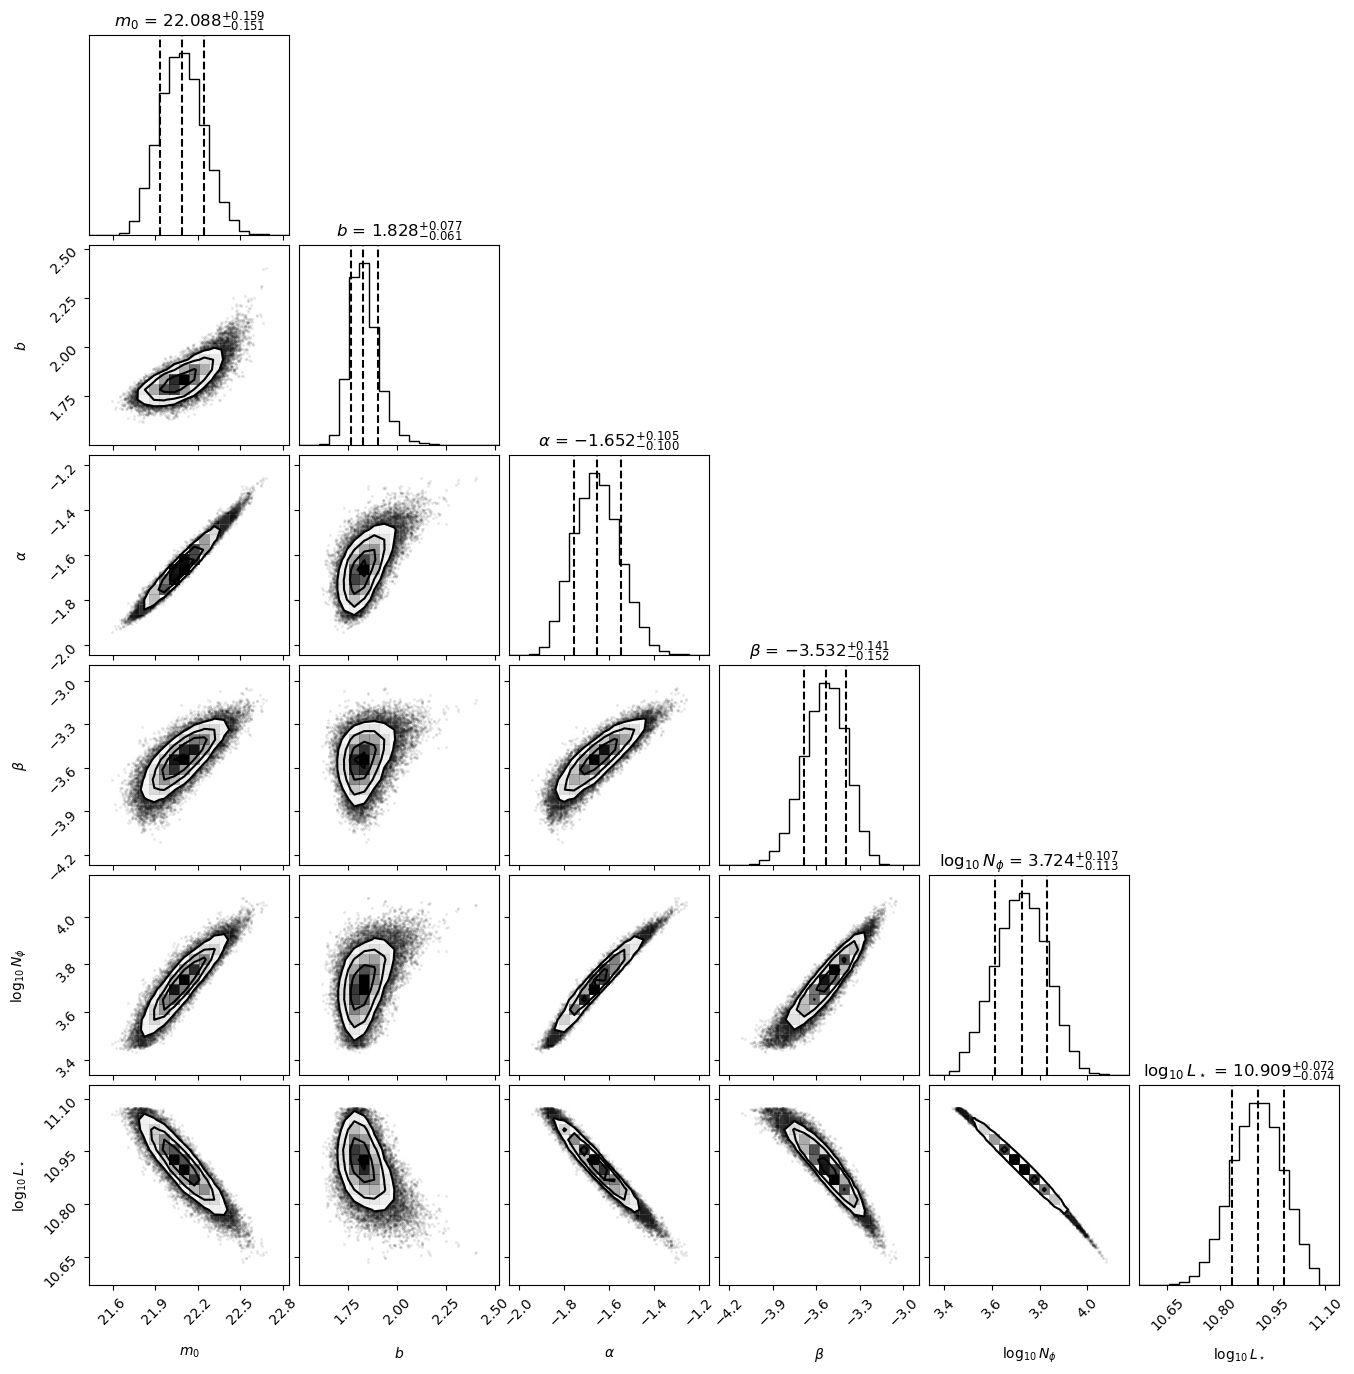

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import corner


samples = np.column_stack([
    d["m0"],
    d["b"],
    d["alpha"],
    d["beta"],
    d["log_Nphi"] / np.log(10.0),
    d["log_Lstar"] / np.log(10.0),
])

labels = [
    r"$m_0$",
    r"$b$",
    r"$\alpha$",
    r"$\beta$",
    r"$\log_{10} N_\phi$",
    r"$\log_{10} L_\star$",
]

ranges = []
for j in range(samples.shape[1]):
    v = samples[:, j]
    lo, hi = v.min(), v.max()
    pad = 0.15 * (hi - lo)
    ranges.append((lo - pad, hi + pad))

fig = corner.corner(
    samples,
    labels=labels,
    range=ranges,
    show_titles=True,
    title_fmt=".3f",
    quantiles=[0.16, 0.5, 0.84],
)
plt.show()

In [16]:

logL = d["log_Lstar"] / np.log(10)   # convert to log10
logN = d["log_Nphi"] / np.log(10)

# your prior bounds in log10
logL_lo, logL_hi = 24/np.log(10), 25.5/np.log(10)

# how many samples near upper boundary?
frac_high = np.mean(logL > (logL_hi - 0.02))
frac_low  = np.mean(logL < (logL_lo + 0.02))

print("Fraction near upper bound:", frac_high)
print("Fraction near lower bound:", frac_low)

Fraction near upper bound: 0.036375
Fraction near lower bound: 0.0
